# 02 · Modelagem: comparação de comitês

Comparação entre membros individuais, um comitê heterogêneo e dois comitês homogêneos (redução de variância e redução de viés), todos sob o mesmo protocolo.

| Regra (enunciado §3) | Como está garantido |
|---|---|
| Teste separado no início e usado uma vez | `dataset/splits/test.csv`, só lido por `load_test()` na seção 13 |
| Pré-processamento dentro de pipeline | toda alternativa é `Pipeline([("prep", build_preprocessor()), ("model", ...)])`, ajustado só no treino de cada dobra |
| Mesmas divisões para todas as alternativas | `cv = get_cv()` (10 dobras estratificadas, semente 42) como laço externo de todas as alternativas |
| Esforço de ajuste equivalente | `RandomizedSearchCV` com `n_iter = 20` e CV interna de 5 dobras para cada alternativa ajustável (CV aninhada) |
| Sementes fixas | `C.SEED = 42` em divisões, buscas e `random_state` de todos os modelos estocásticos |
| Dispersão reportada | média ± desvio-padrão entre as 10 dobras externas e comparação pareada dobra a dobra |

In [1]:
import sys
from pathlib import Path

_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "tde2").is_dir())
sys.path.insert(0, str(_root / "src"))

In [2]:
import platform
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import UndefinedMetricWarning
from sklearn.metrics import ConfusionMatrixDisplay

from tde2 import config as C
from tde2 import evaluation as E
from tde2 import models as M
from tde2.data import get_cv, load_train

warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

C.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR = C.ROOT / "reports" / "tables"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 3)

COLORS = {0: "#2a78d6", 1: "#eb6834"}
FAMILY_COLORS = {
    "linha de base": "#8a8984",
    "membro": "#2a78d6",
    "heterogêneo": "#eb6834",
    "homogêneo (variância)": "#1f9e6e",
    "homogêneo (viés)": "#8f4fc9",
}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "font.size": 10,
})

X_train, y_train = load_train()
cv = get_cv()
BASELINE = "Linha de base (classe majoritária)"
FAMILY = {BASELINE: "linha de base", **M.FAMILY}
results = {}
tuning_time = {}
print(X_train.shape, y_train.value_counts().to_dict())

(612, 11) {1: 339, 0: 273}


In [3]:
def run(name, estimator):
    t0 = time.perf_counter()
    results[name] = E.evaluate(name, estimator, X_train, y_train, cv)
    tuning_time[name] = time.perf_counter() - t0
    return results[name]


def show(names):
    return E.formatted(E.summary({n: results[n] for n in names}, FAMILY))

## 1. Linha de base

Classificador da classe majoritária (sempre "Doença cardíaca"), avaliado com as mesmas dobras e métricas.

In [4]:
run(BASELINE, M.pipeline(DummyClassifier(strategy="most_frequent")))
show([BASELINE])

,família,balanced_accuracy,f1_macro,recall_doenca,roc_auc
modelo,,,,,
Linha de base (classe majoritária),linha de base,0.500 ± 0.000,0.356 ± 0.002,1.000 ± 0.000,0.500 ± 0.000


## 2. Protocolo de ajuste

- **Métrica principal:** acurácia balanceada (`balanced_accuracy`). Também são reportados F1-macro, recall da classe doença e ROC-AUC.
- **CV aninhada:** laço externo = `get_cv()` (10 dobras, as mesmas para todas as alternativas); laço interno = `StratifiedKFold(5, shuffle=True, random_state=42)` sobre o treino de cada dobra externa.
- **Orçamento:** `RandomizedSearchCV(n_iter=20, scoring="balanced_accuracy", random_state=42)` para cada membro e cada comitê homogêneo.
- **Comitê heterogêneo:** cada membro é a sua própria busca (mesmo orçamento), dentro do `VotingClassifier`; a fusão não tem hiperparâmetros adicionais.
- **Pré-processamento:** `build_preprocessor(scale=True)` para todas as alternativas.

Espaços de busca:

In [5]:
def describe(v):
    if isinstance(v, list):
        return ", ".join(map(str, v))
    name, args = v.dist.name, v.args
    if name == "randint":
        return f"inteiro uniforme em [{args[0]}, {args[1] - 1}]"
    if name == "uniform":
        return f"uniforme em [{args[0]:g}, {args[0] + args[1]:g}]"
    if name in ("loguniform", "reciprocal"):
        return f"log-uniforme em [{args[0]:g}, {args[1]:g}]"
    return f"{name}{args}"


spaces = pd.DataFrame(
    [{"alternativa": n, "hiperparâmetro": k, "espaço": describe(v)}
     for n, space in M.search_spaces().items() for k, v in space.items()]
).set_index(["alternativa", "hiperparâmetro"])
spaces.to_csv(TABLES_DIR / "02_espacos_busca.csv")
spaces

espaço
alternativa         hiperparâmetro                                         
Regressão logística C                          log-uniforme em [0.001, 100]
                    class_weight                             None, balanced
KNN                 n_neighbors                 inteiro uniforme em [1, 50]
                    weights                               uniform, distance
                    p                                                  1, 2
SVM (RBF)           estimator__C                log-uniforme em [0.01, 100]
                    estimator__gamma            log-uniforme em [0.0001, 1]
                    estimator__class_weight                  None, balanced
Árvore de decisão   max_depth                None, 2, 3, 4, 5, 6, 8, 10, 12
                    min_samples_leaf            inteiro uniforme em [1, 30]
                    criterion                                 gini, entropy
Naive Bayes         var_smoothing              log-uniforme em [1e-12, 0.1]
Toco de decisão     min_samples_leaf            inteiro uniforme em [1, 50]
                    criterion                                 gini, entropy
                    class_weight                             None, balanced
Random Forest       n_estimators              inteiro uniforme em [50, 500]
                    max_depth                None, 2, 3, 4, 5, 6, 8, 10, 12
                    min_samples_leaf            inteiro uniforme em [1, 20]
                    max_features                      sqrt, log2, 0.5, None
Bagging de árvores  n_estimators              inteiro uniforme em [10, 300]
                    max_samples                        uniforme em [0.3, 1]
                    max_features                       uniforme em [0.3, 1]
                    estimator__max_depth     None, 2, 3, 4, 5, 6, 8, 10, 12
Gradient Boosting   n_estimators              inteiro uniforme em [50, 500]
                    learning_rate               log-uniforme em [0.01, 0.5]
                    max_depth                    inteiro uniforme em [1, 5]
                    subsample                          uniforme em [0.5, 1]
AdaBoost            n_estimators              inteiro uniforme em [50, 500]
                    learning_rate                 log-uniforme em [0.01, 2]

## 3. Membros individuais

Os cinco membros do comitê heterogêneo (regressão logística, KNN, SVM com kernel RBF (probabilidades por calibração sigmoide, `CalibratedClassifierCV(SVC(), ensemble=False)`), árvore de decisão e Naive Bayes gaussiano), mais o toco de decisão (árvore de profundidade 1), que é o membro-base do AdaBoost. A árvore de decisão é o membro-base do Random Forest e do Bagging.

In [6]:
for name in M.MEMBERS + [M.STUMP]:
    run(name, M.nested(name))
show(M.MEMBERS + [M.STUMP])

,família,balanced_accuracy,f1_macro,recall_doenca,roc_auc
modelo,,,,,
Regressão logística,membro,0.851 ± 0.033,0.850 ± 0.032,0.870 ± 0.046,0.928 ± 0.019
KNN,membro,0.853 ± 0.024,0.855 ± 0.022,0.897 ± 0.042,0.922 ± 0.020
SVM (RBF),membro,0.841 ± 0.034,0.842 ± 0.031,0.894 ± 0.039,0.919 ± 0.019
Árvore de decisão,membro,0.821 ± 0.020,0.821 ± 0.022,0.844 ± 0.064,0.896 ± 0.023
Naive Bayes,membro,0.842 ± 0.040,0.841 ± 0.039,0.856 ± 0.059,0.914 ± 0.023
Toco de decisão,membro,0.811 ± 0.027,0.811 ± 0.027,0.855 ± 0.069,0.811 ± 0.027


## 4. Comitê heterogêneo (Aula 6)

- **Membros:** os cinco da seção 3, cada um ajustado pela sua busca dentro de cada dobra externa.
- **Regra de fusão principal: votação suave.** A probabilidade da classe doença é a média simples (pesos iguais) das `predict_proba` dos cinco membros; prediz-se a classe de maior probabilidade média.
- **Variante: votação dura** (maioria simples dos cinco votos), avaliada para comparação. Não tem `predict_proba`, então não tem ROC-AUC.

In [7]:
for name in M.HETEROGENEOUS:
    run(name, M.nested(name))
show(M.MEMBERS + M.HETEROGENEOUS)

,família,balanced_accuracy,f1_macro,recall_doenca,roc_auc
modelo,,,,,
Regressão logística,membro,0.851 ± 0.033,0.850 ± 0.032,0.870 ± 0.046,0.928 ± 0.019
KNN,membro,0.853 ± 0.024,0.855 ± 0.022,0.897 ± 0.042,0.922 ± 0.020
SVM (RBF),membro,0.841 ± 0.034,0.842 ± 0.031,0.894 ± 0.039,0.919 ± 0.019
Árvore de decisão,membro,0.821 ± 0.020,0.821 ± 0.022,0.844 ± 0.064,0.896 ± 0.023
Naive Bayes,membro,0.842 ± 0.040,0.841 ± 0.039,0.856 ± 0.059,0.914 ± 0.023
Votação suave,heterogêneo,0.848 ± 0.039,0.848 ± 0.037,0.882 ± 0.053,0.928 ± 0.015
Votação dura,heterogêneo,0.849 ± 0.037,0.850 ± 0.035,0.888 ± 0.041,—


## 5. Comitê homogêneo, redução de variância (Aula 9)

- **Random Forest:** árvores em amostras bootstrap com subconjunto aleatório de atributos em cada nó.
- **Bagging de árvores:** `BaggingClassifier` com árvores de decisão, amostrando exemplos e atributos.
- **Membro-base:** árvore de decisão (seção 3).

In [8]:
for name in M.VARIANCE:
    run(name, M.nested(name))
show([M.TREE] + M.VARIANCE)

,família,balanced_accuracy,f1_macro,recall_doenca,roc_auc
modelo,,,,,
Árvore de decisão,membro,0.821 ± 0.020,0.821 ± 0.022,0.844 ± 0.064,0.896 ± 0.023
Random Forest,homogêneo (variância),0.847 ± 0.030,0.849 ± 0.028,0.900 ± 0.061,0.929 ± 0.018
Bagging de árvores,homogêneo (variância),0.850 ± 0.032,0.852 ± 0.031,0.906 ± 0.057,0.920 ± 0.018


## 6. Comitê homogêneo, redução de viés (Aula 9)

- **AdaBoost:** tocos de decisão (profundidade 1) reponderados sequencialmente (SAMME). Membro-base: toco de decisão (seção 3).
- **Gradient Boosting:** árvores de regressão rasas ajustadas ao gradiente da perda logística. Os membros internos são regressores, então a árvore de decisão é usada como membro de referência.

In [9]:
for name in M.BIAS:
    run(name, M.nested(name))
show([M.STUMP, M.TREE] + M.BIAS)

,família,balanced_accuracy,f1_macro,recall_doenca,roc_auc
modelo,,,,,
Toco de decisão,membro,0.811 ± 0.027,0.811 ± 0.027,0.855 ± 0.069,0.811 ± 0.027
Árvore de decisão,membro,0.821 ± 0.020,0.821 ± 0.022,0.844 ± 0.064,0.896 ± 0.023
Gradient Boosting,homogêneo (viés),0.846 ± 0.032,0.845 ± 0.030,0.867 ± 0.051,0.921 ± 0.026
AdaBoost,homogêneo (viés),0.847 ± 0.039,0.846 ± 0.037,0.858 ± 0.046,0.920 ± 0.018


## 7. Tabela de resultados

Média ± desvio-padrão entre as 10 dobras externas (CV aninhada). Mesmas dobras para todas as linhas.

In [10]:
ORDER = [BASELINE] + M.MEMBERS + [M.STUMP] + M.COMMITTEES
table = E.summary({n: results[n] for n in ORDER}, FAMILY)
table.to_csv(TABLES_DIR / "02_resultados_cv.csv")
E.formatted(table)

,família,balanced_accuracy,f1_macro,recall_doenca,roc_auc
modelo,,,,,
Linha de base (classe majoritária),linha de base,0.500 ± 0.000,0.356 ± 0.002,1.000 ± 0.000,0.500 ± 0.000
Regressão logística,membro,0.851 ± 0.033,0.850 ± 0.032,0.870 ± 0.046,0.928 ± 0.019
KNN,membro,0.853 ± 0.024,0.855 ± 0.022,0.897 ± 0.042,0.922 ± 0.020
SVM (RBF),membro,0.841 ± 0.034,0.842 ± 0.031,0.894 ± 0.039,0.919 ± 0.019
Árvore de decisão,membro,0.821 ± 0.020,0.821 ± 0.022,0.844 ± 0.064,0.896 ± 0.023
Naive Bayes,membro,0.842 ± 0.040,0.841 ± 0.039,0.856 ± 0.059,0.914 ± 0.023
Toco de decisão,membro,0.811 ± 0.027,0.811 ± 0.027,0.855 ± 0.069,0.811 ± 0.027
Votação suave,heterogêneo,0.848 ± 0.039,0.848 ± 0.037,0.882 ± 0.053,0.928 ± 0.015
Votação dura,heterogêneo,0.849 ± 0.037,0.850 ± 0.035,0.888 ± 0.041,—


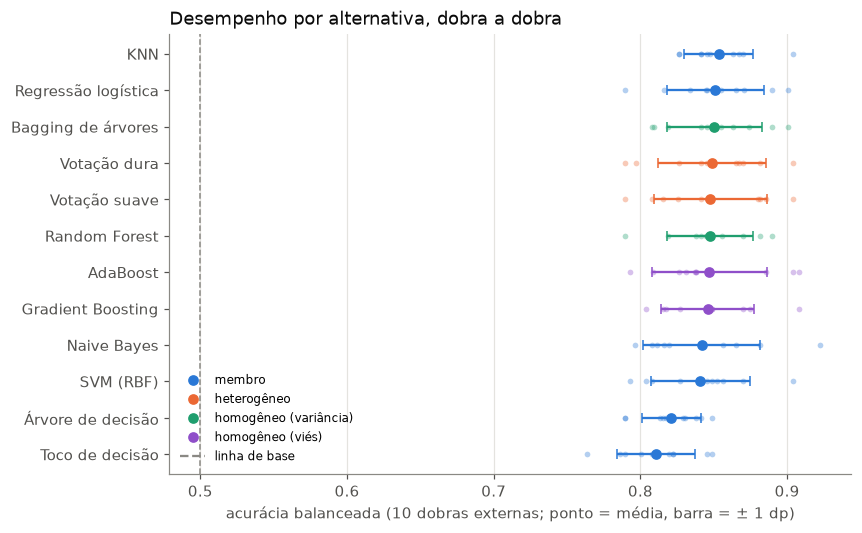

In [11]:
folds = pd.DataFrame({n: results[n].folds[C.PRIMARY_METRIC] for n in ORDER[1:]})
order = folds.mean().sort_values().index

fig, ax = plt.subplots(figsize=(8, 5.2))
for i, n in enumerate(order):
    color = FAMILY_COLORS[FAMILY[n]]
    ax.scatter(folds[n], np.full(len(folds), i), s=14, color=color, alpha=0.35, linewidths=0)
    m, s = folds[n].mean(), folds[n].std(ddof=1)
    ax.errorbar(m, i, xerr=s, fmt="o", color=color, ms=6, capsize=3, lw=1.5)
ax.axvline(results[BASELINE].folds[C.PRIMARY_METRIC].mean(), color="#8a8984", ls="--", lw=1)
ax.set_yticks(range(len(order)), order)
ax.grid(axis="y", visible=False)
ax.set_xlabel("acurácia balanceada (10 dobras externas; ponto = média, barra = ± 1 dp)")
handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=f) for f, c in FAMILY_COLORS.items() if f != "linha de base"]
handles.append(plt.Line2D([], [], ls="--", color="#8a8984", label="linha de base"))
ax.legend(handles=handles, frameon=False, loc="lower left", fontsize=8)
ax.set_title("Desempenho por alternativa, dobra a dobra", loc="left", color="#0b0b0b")
fig.savefig(C.FIGURES_DIR / "02_desempenho_dobras.png")
plt.show()

## 8. Comparações pareadas

Como as dobras são as mesmas, cada par é comparado pela diferença dobra a dobra da acurácia balanceada (A − B).

**Critério combinado:** só se afirma que A supera B se (i) o teste t pareado com correção de Nadeau e Bengio (2003), que leva em conta a sobreposição dos treinos entre dobras, der p < 0,05, **e** (ii) a diferença média for maior que o desvio-padrão das diferenças entre dobras.

In [12]:
best_member = {c: max(refs, key=lambda n: results[n].folds[C.PRIMARY_METRIC].mean())
               for c, refs in M.REFERENCE_MEMBERS.items()}
vs_member = E.comparisons([(c, best_member[c]) for c in M.COMMITTEES], results)
vs_member.to_csv(TABLES_DIR / "02_comites_vs_melhor_membro.csv", index=False)
vs_member

,A,B,dif_media,dif_dp,dobras_A_melhor,dobras_empate,t_corrigido,p_valor,A_supera_B,B_supera_A
0,Votação suave,KNN,-0.006,0.026,3,3,-0.465,0.653,False,False
1,Votação dura,KNN,-0.004,0.018,2,5,-0.542,0.601,False,False
2,Random Forest,Árvore de decisão,0.026,0.037,8,0,1.559,0.153,False,False
3,Bagging de árvores,Árvore de decisão,0.029,0.040,7,0,1.600,0.144,False,False
4,Gradient Boosting,Árvore de decisão,0.025,0.037,6,1,1.459,0.179,False,False
5,AdaBoost,Toco de decisão,0.036,0.046,8,0,1.706,0.122,False,False


In [13]:
best_overall_member = max(M.MEMBERS + [M.STUMP], key=lambda n: results[n].folds[C.PRIMARY_METRIC].mean())
pairs = [(a, b) for i, a in enumerate(M.COMMITTEES) for b in M.COMMITTEES[i + 1:]]
pairs += [(c, best_overall_member) for c in M.COMMITTEES if best_member[c] != best_overall_member]
pairs += [(n, BASELINE) for n in M.MEMBERS + [M.STUMP] + M.COMMITTEES]
all_pairs = E.comparisons(pairs, results)
all_pairs.to_csv(TABLES_DIR / "02_comparacoes_pareadas.csv", index=False)
print("Melhor membro individual (média CV):", best_overall_member)
all_pairs

Melhor membro individual (média CV): KNN


,A,B,dif_media,dif_dp,dobras_A_melhor,dobras_empate,t_corrigido,p_valor,A_supera_B,B_supera_A
0,Votação suave,Votação dura,-1.045e-03,0.019,3,5,-0.121,9.066e-01,False,False
1,Votação suave,Random Forest,3.035e-04,0.030,5,2,0.022,9.831e-01,False,False
2,Votação suave,Bagging de árvores,-2.770e-03,0.035,3,3,-0.173,8.669e-01,False,False
3,Votação suave,Gradient Boosting,1.931e-03,0.046,4,0,0.091,9.294e-01,False,False
4,Votação suave,AdaBoost,8.318e-04,0.023,3,1,0.080,9.382e-01,False,False
5,Votação dura,Random Forest,1.348e-03,0.031,4,3,0.096,9.259e-01,False,False
6,Votação dura,Bagging de árvores,-1.725e-03,0.037,5,2,-0.102,9.210e-01,False,False
7,Votação dura,Gradient Boosting,2.976e-03,0.042,4,1,0.155,8.800e-01,False,False
8,Votação dura,AdaBoost,1.877e-03,0.025,4,1,0.163,8.741e-01,False,False
9,Random Forest,Bagging de árvores,-3.073e-03,0.019,2,4,-0.362,7.261e-01,False,False


## 9. Diversidade e ganho

Medidas sobre as saídas "oráculo" (acertou / errou) de cada par de membros, calculadas nas predições de validação de cada dobra externa e depois promediadas (Kuncheva e Whitaker, 2003):

- **Discordância:** proporção de exemplos em que exatamente um dos dois membros acerta. Maior = mais diverso.
- **Q de Yule:** de −1 a 1; perto de 1 = os membros acertam e erram nos mesmos exemplos. Menor = mais diverso.

Comitê heterogêneo: entre os 5 membros ajustados dentro do comitê. Random Forest, Bagging e AdaBoost: entre todos os seus estimadores internos. Gradient Boosting: não se aplica (os estimadores internos são árvores de regressão sobre o gradiente, não classificadores).

**Ganho** = acurácia balanceada média do comitê − a do melhor membro de referência.

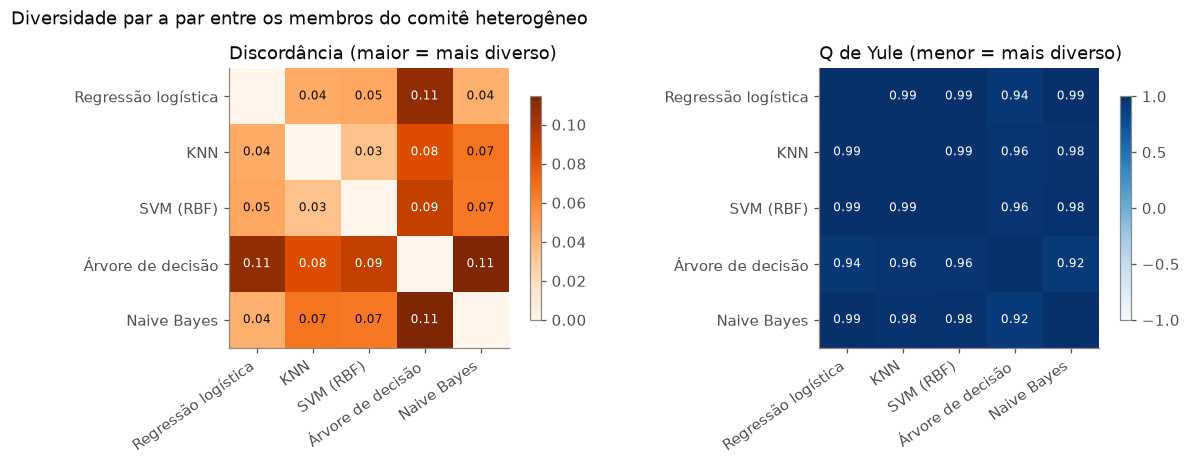

In [14]:
member_dis, member_q = [], []
for est, idx in zip(results[M.SOFT_VOTING].estimators, results[M.SOFT_VOTING].test_idx):
    correct = E.oracle(E.internal_predictions(est, X_train.iloc[idx]), y_train.iloc[idx])
    member_dis.append(E.disagreement_matrix(correct))
    member_q.append(E.q_matrix(correct))
member_dis = pd.DataFrame(np.mean(member_dis, axis=0), index=M.MEMBERS, columns=M.MEMBERS)
member_q = pd.DataFrame(np.nanmean(member_q, axis=0), index=M.MEMBERS, columns=M.MEMBERS)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (title, mat, cmap, lims) in zip(axes, [
    ("Discordância (maior = mais diverso)", member_dis, "Oranges", (0, member_dis.values.max())),
    ("Q de Yule (menor = mais diverso)", member_q, "Blues", (-1, 1)),
]):
    im = ax.imshow(mat.values, cmap=cmap, vmin=lims[0], vmax=lims[1])
    ax.set_xticks(range(len(mat)), mat.columns, rotation=35, ha="right")
    ax.set_yticks(range(len(mat)), mat.index)
    ax.grid(False)
    for i in range(len(mat)):
        for j in range(len(mat)):
            if i != j:
                ax.text(j, i, f"{mat.values[i, j]:.2f}", ha="center", va="center", fontsize=8,
                        color="white" if im.norm(mat.values[i, j]) > 0.6 else "#0b0b0b")
    ax.set_title(title, loc="left", color="#0b0b0b")
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.suptitle("Diversidade par a par entre os membros do comitê heterogêneo", x=0.01, ha="left", color="#0b0b0b")
fig.tight_layout()
fig.savefig(C.FIGURES_DIR / "02_diversidade_heterogeneo.png")
plt.show()

In [15]:
rows = []
for c in M.COMMITTEES:
    div = E.internal_diversity(results[c], X_train, y_train) or {"discordancia": np.nan, "q_yule": np.nan}
    cmp = vs_member.set_index("A").loc[c]
    rows.append({
        "comitê": c,
        "família": FAMILY[c],
        "discordância": div["discordancia"],
        "q_yule": div["q_yule"],
        "melhor_membro_ref": best_member[c],
        "ganho_vs_melhor_membro": cmp["dif_media"],
        "dp_dif": cmp["dif_dp"],
        "p_valor": cmp["p_valor"],
        "supera_melhor_membro": cmp["A_supera_B"],
    })
diversity = pd.DataFrame(rows).set_index("comitê")
diversity.to_csv(TABLES_DIR / "02_diversidade_ganho.csv")
diversity

,família,discordância,q_yule,melhor_membro_ref,ganho_vs_melhor_membro,dp_dif,p_valor,supera_melhor_membro
comitê,,,,,,,,
Votação suave,heterogêneo,0.070,0.970,KNN,-0.006,0.026,0.653,False
Votação dura,heterogêneo,0.070,0.970,KNN,-0.004,0.018,0.601,False
Random Forest,homogêneo (variância),0.199,0.733,Árvore de decisão,0.026,0.037,0.153,False
Bagging de árvores,homogêneo (variância),0.272,0.540,Árvore de decisão,0.029,0.040,0.144,False
Gradient Boosting,homogêneo (viés),NaN,NaN,Árvore de decisão,0.025,0.037,0.179,False
AdaBoost,homogêneo (viés),0.482,0.017,Toco de decisão,0.036,0.046,0.122,False


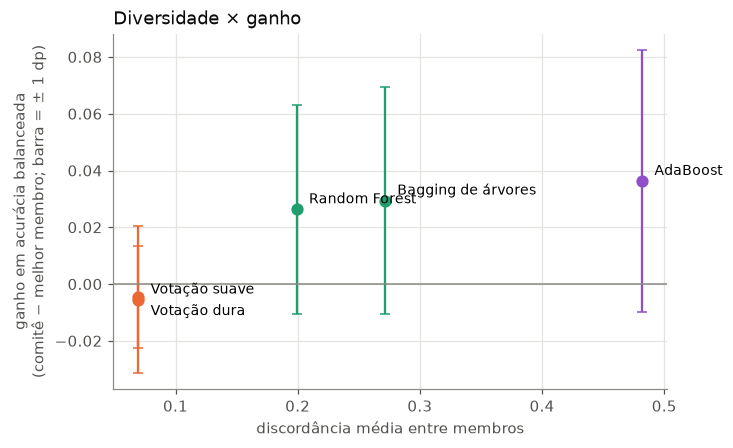

In [16]:
d = diversity.dropna(subset=["discordância"])
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for c, r in d.iterrows():
    ax.errorbar(r["discordância"], r["ganho_vs_melhor_membro"], yerr=r["dp_dif"], fmt="o",
                color=FAMILY_COLORS[r["família"]], capsize=3, ms=7)
    ax.annotate(c, (r["discordância"], r["ganho_vs_melhor_membro"]), xytext=(8, -12 if c == M.HARD_VOTING else 4),
                textcoords="offset points", fontsize=9)
ax.axhline(0, color="#8a8984", lw=1)
ax.set_xlabel("discordância média entre membros")
ax.set_ylabel("ganho em acurácia balanceada\n(comitê − melhor membro; barra = ± 1 dp)")
ax.set_title("Diversidade × ganho", loc="left", color="#0b0b0b")
fig.savefig(C.FIGURES_DIR / "02_diversidade_ganho.png")
plt.show()

## 10. Erros por classe

Matrizes de confusão das predições fora da dobra (cada exemplo do treino é predito uma vez, pelo modelo que não o viu), somadas nas 10 dobras externas.

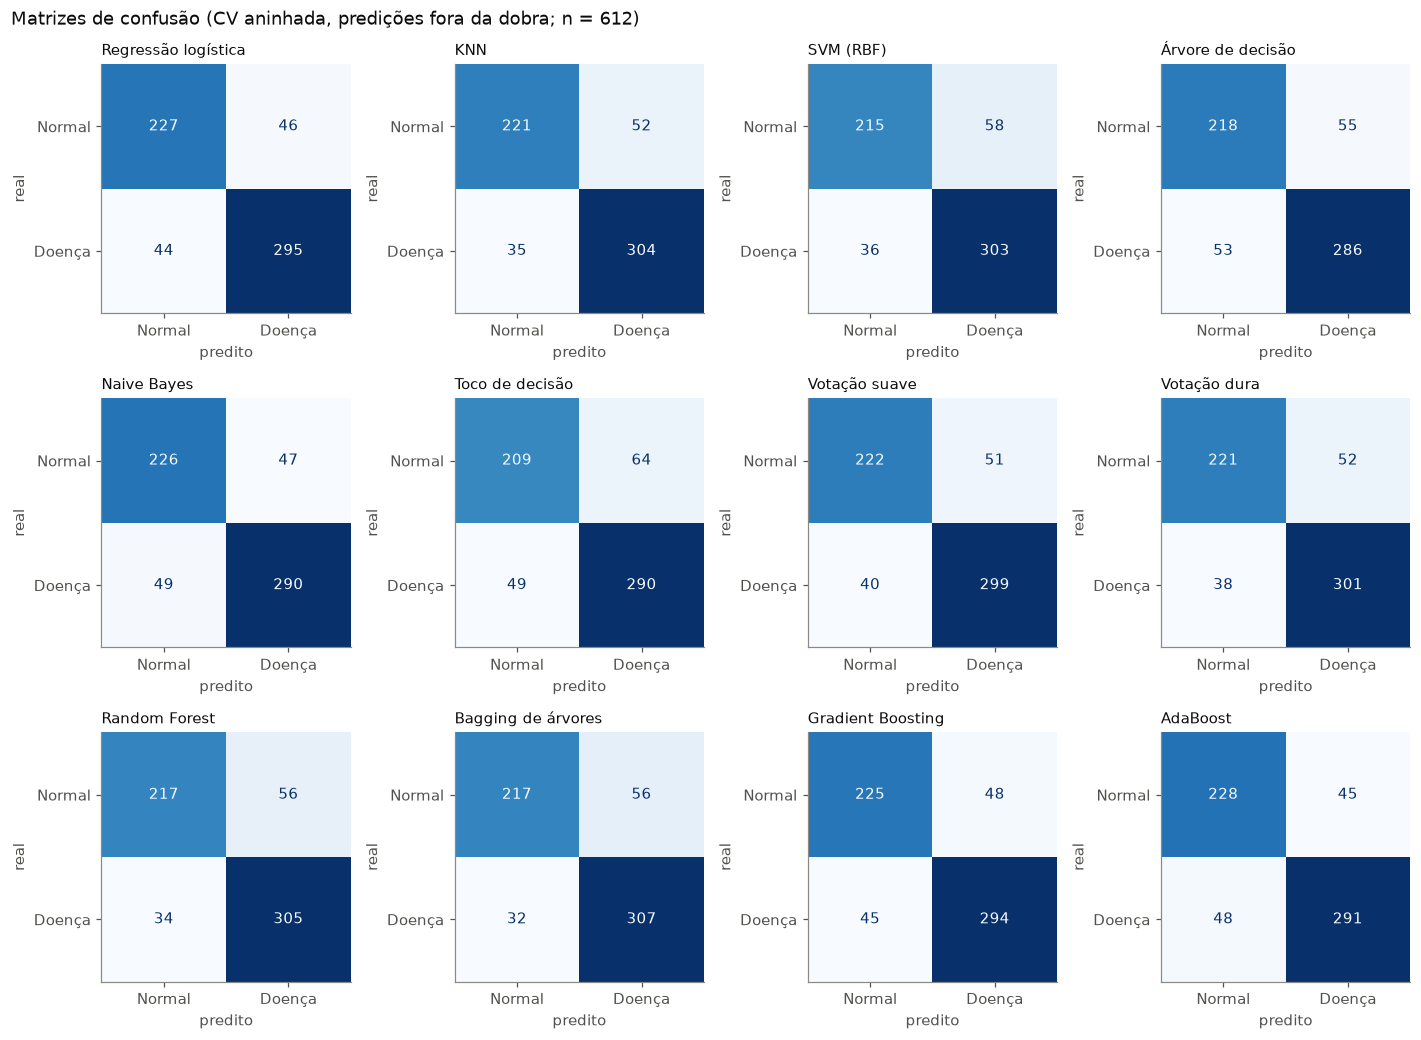

In [17]:
ALTS = M.MEMBERS + [M.STUMP] + M.COMMITTEES
labels = ["Normal", "Doença"]
fig, axes = plt.subplots(3, 4, figsize=(13, 9.6))
for ax, n in zip(axes.flat, ALTS):
    ConfusionMatrixDisplay.from_predictions(
        y_train, results[n].pred, display_labels=labels, cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(n, loc="left", color="#0b0b0b", fontsize=10)
    ax.grid(False)
    ax.set_xlabel("predito")
    ax.set_ylabel("real")
fig.suptitle("Matrizes de confusão (CV aninhada, predições fora da dobra; n = 612)", x=0.01, ha="left", color="#0b0b0b")
fig.tight_layout()
fig.savefig(C.FIGURES_DIR / "02_matrizes_confusao_cv.png")
plt.show()

In [18]:
per_class = pd.DataFrame({n: E.per_class(results[n], y_train) for n in [BASELINE] + ALTS}).T
per_class.to_csv(TABLES_DIR / "02_erros_por_classe_cv.csv")
per_class

,VN,FP,FN,VP,recall_Normal,recall_Doença cardíaca,precisão_doença
Linha de base (classe majoritária),0.0,273.0,0.0,339.0,0.000,1.000,0.554
Regressão logística,227.0,46.0,44.0,295.0,0.832,0.870,0.865
KNN,221.0,52.0,35.0,304.0,0.810,0.897,0.854
SVM (RBF),215.0,58.0,36.0,303.0,0.788,0.894,0.839
Árvore de decisão,218.0,55.0,53.0,286.0,0.799,0.844,0.839
Naive Bayes,226.0,47.0,49.0,290.0,0.828,0.855,0.861
Toco de decisão,209.0,64.0,49.0,290.0,0.766,0.855,0.819
Votação suave,222.0,51.0,40.0,299.0,0.813,0.882,0.854
Votação dura,221.0,52.0,38.0,301.0,0.810,0.888,0.853
Random Forest,217.0,56.0,34.0,305.0,0.795,0.900,0.845


Taxa de erro fora da dobra por subgrupo do treino (onde cada alternativa falha):

In [19]:
groups = {
    "Cholesterol = 0": X_train["Cholesterol"] == 0,
    "Cholesterol > 0": X_train["Cholesterol"] > 0,
    "Sex = F": X_train["Sex"] == "F",
    "Sex = M": X_train["Sex"] == "M",
    "ChestPainType = ASY": X_train["ChestPainType"] == "ASY",
    "ChestPainType ≠ ASY": X_train["ChestPainType"] != "ASY",
    "ExerciseAngina = Y": X_train["ExerciseAngina"] == "Y",
    "ExerciseAngina = N": X_train["ExerciseAngina"] == "N",
}
err = {n: (results[n].pred != y_train.to_numpy()) for n in ALTS}
subgroup = pd.DataFrame(
    {g: {"n": int(mask.sum()), "% doença": y_train[mask].mean(), **{n: e[mask.to_numpy()].mean() for n, e in err.items()}}
     for g, mask in groups.items()}
).T
subgroup.to_csv(TABLES_DIR / "02_erro_por_subgrupo_cv.csv")
subgroup

,n,% doença,Regressão logística,KNN,SVM (RBF),Árvore de decisão,Naive Bayes,Toco de decisão,Votação suave,Votação dura,Random Forest,Bagging de árvores,Gradient Boosting,AdaBoost
Cholesterol = 0,109.0,0.899,0.055,0.083,0.083,0.147,0.092,0.211,0.092,0.073,0.101,0.092,0.083,0.083
Cholesterol > 0,503.0,0.479,0.167,0.155,0.169,0.183,0.171,0.179,0.161,0.163,0.157,0.155,0.167,0.167
Sex = F,129.0,0.279,0.171,0.194,0.202,0.240,0.140,0.233,0.178,0.194,0.178,0.178,0.202,0.155
Sex = M,483.0,0.627,0.141,0.128,0.141,0.159,0.161,0.172,0.141,0.135,0.139,0.135,0.139,0.151
ChestPainType = ASY,335.0,0.788,0.140,0.131,0.134,0.164,0.137,0.182,0.128,0.131,0.128,0.131,0.143,0.140
ChestPainType ≠ ASY,277.0,0.271,0.155,0.155,0.177,0.191,0.181,0.188,0.173,0.166,0.170,0.159,0.162,0.166
ExerciseAngina = Y,253.0,0.842,0.134,0.119,0.126,0.138,0.142,0.166,0.119,0.123,0.130,0.123,0.150,0.142
ExerciseAngina = N,359.0,0.351,0.156,0.159,0.173,0.203,0.167,0.198,0.170,0.164,0.159,0.159,0.153,0.159


In [20]:
err_committees = np.array([err[c] for c in M.COMMITTEES])
n_wrong = err_committees.sum(axis=0)
overlap = pd.Series(n_wrong).value_counts().sort_index().rename_axis("nº de comitês que erram").rename("exemplos")
hard = X_train[n_wrong == len(M.COMMITTEES)].assign(**{C.TARGET: y_train[n_wrong == len(M.COMMITTEES)]})
print(f"Exemplos errados por todos os {len(M.COMMITTEES)} comitês: {len(hard)}, "
      f"dos quais {int(hard[C.TARGET].sum())} com doença (falsos negativos) e {int((hard[C.TARGET] == 0).sum())} normais (falsos positivos)")
overlap.to_frame().T

Exemplos errados por todos os 6 comitês: 56, dos quais 21 com doença (falsos negativos) e 35 normais (falsos positivos)


nº de comitês que erram,0,1,2,3,4,5,6
exemplos,478,26,13,14,10,15,56


In [21]:
hard

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak,FastingBS,Sex,ChestPainType,RestingECG,ExerciseAngina,ST_Slope,HeartDisease
row_id,,,,,,,,,,,,
26,53,124,260,112,3.0,0,M,ASY,ST,Y,Flat,0
39,48,150,227,130,1.0,0,F,ASY,Normal,Y,Flat,0
45,59,130,318,120,1.0,0,M,NAP,Normal,Y,Flat,0
54,52,130,180,140,1.5,0,F,ASY,Normal,Y,Flat,0
89,55,140,229,110,0.5,0,M,ASY,Normal,Y,Flat,0
134,61,130,294,120,1.0,0,F,ASY,ST,Y,Flat,0
144,56,120,279,150,1.0,0,F,ATA,Normal,N,Flat,1
183,46,110,238,140,1.0,0,M,ASY,ST,Y,Flat,0
188,50,120,328,110,1.0,0,F,ASY,Normal,Y,Flat,0


## 11. Configurações congeladas

A busca de cada alternativa (mesmo orçamento: 20 configurações, CV interna de 5 dobras) é refeita sobre o treino inteiro, e a melhor configuração é congelada. São essas configurações que medem o custo (seção 12) e vão ao teste (seção 13). Os comitês heterogêneos usam os membros congelados.

In [22]:
frozen, searches = M.freeze(X_train, y_train)
frozen[BASELINE] = M.pipeline(DummyClassifier(strategy="most_frequent"))
params = pd.DataFrame(
    [{"alternativa": n, "hiperparâmetro": k.removeprefix("model__"), "valor": v}
     for n, s in searches.items() for k, v in s.best_params_.items()]
).set_index(["alternativa", "hiperparâmetro"])
params["valor"] = params["valor"].map(lambda v: f"{v:.4g}" if isinstance(v, float) else str(v))
params.to_csv(TABLES_DIR / "02_hiperparametros_congelados.csv")
params

valor
alternativa         hiperparâmetro                    
Regressão logística C                           0.1695
                    class_weight                  None
KNN                 n_neighbors                     44
                    p                                1
                    weights                   distance
SVM (RBF)           estimator__C                 13.15
                    estimator__class_weight       None
                    estimator__gamma         0.0004208
Árvore de decisão   criterion                  entropy
                    max_depth                       10
                    min_samples_leaf                12
Naive Bayes         var_smoothing             0.003372
Toco de decisão     class_weight                  None
                    criterion                  entropy
                    min_samples_leaf                29
Random Forest       max_depth                        6
                    max_features                  log2
                    min_samples_leaf                 1
                    n_estimators                   363
Bagging de árvores  estimator__max_depth            10
                    max_features                0.5497
                    max_samples                 0.4967
                    n_estimators                    50
Gradient Boosting   learning_rate              0.04328
                    max_depth                        5
                    n_estimators                   320
                    subsample                    0.866
AdaBoost            learning_rate               0.1061
                    n_estimators                   264

In [23]:
pd.DataFrame({n: {"score_busca_interna": s.best_score_} for n, s in searches.items()}).T

,score_busca_interna
Regressão logística,0.856
KNN,0.863
SVM (RBF),0.847
Árvore de decisão,0.828
Naive Bayes,0.845
Toco de decisão,0.810
Random Forest,0.854
Bagging de árvores,0.858
Gradient Boosting,0.856
AdaBoost,0.848


## 12. Custo computacional

- **Treino e predição:** configuração congelada, ajustada no treino de cada uma das 10 dobras e usada para predizer a dobra de validação (~61 exemplos). Sem paralelismo (`n_jobs` padrão), uma alternativa por vez.
- **Ajuste:** tempo total da CV aninhada da alternativa (10 dobras × busca de 20 configurações × 5 dobras internas), com a busca paralelizada (`n_jobs=-1`) igualmente para todas.

In [24]:
cost_rows = {}
for n in [BASELINE] + ALTS:
    t = E.timing(frozen[n], X_train, y_train, cv)
    cost_rows[n] = {
        "família": FAMILY[n],
        "treino_ms_media": t["treino_s"].mean() * 1e3,
        "treino_ms_dp": t["treino_s"].std(ddof=1) * 1e3,
        "predicao_ms_media": t["predicao_s"].mean() * 1e3,
        "predicao_ms_dp": t["predicao_s"].std(ddof=1) * 1e3,
        "ajuste_cv_aninhada_s": tuning_time[n],
    }
cost = pd.DataFrame.from_dict(cost_rows, orient="index").rename_axis("modelo")
cost.to_csv(TABLES_DIR / "02_custo.csv")
cost

,família,treino_ms_media,treino_ms_dp,predicao_ms_media,predicao_ms_dp,ajuste_cv_aninhada_s
modelo,,,,,,
Linha de base (classe majoritária),linha de base,3.230,0.260,1.541,0.055,0.127
Regressão logística,membro,3.850,0.065,1.545,0.016,2.726
KNN,membro,3.781,0.495,2.806,0.414,1.490
SVM (RBF),membro,19.394,0.372,2.660,0.110,2.631
Árvore de decisão,membro,4.370,0.139,1.764,0.059,1.275
Naive Bayes,membro,3.671,0.077,1.740,0.074,1.251
Toco de decisão,membro,3.733,0.058,1.693,0.026,1.310
Votação suave,heterogêneo,35.686,1.536,11.085,0.578,8.140
Votação dura,heterogêneo,41.746,6.373,12.826,2.234,7.733


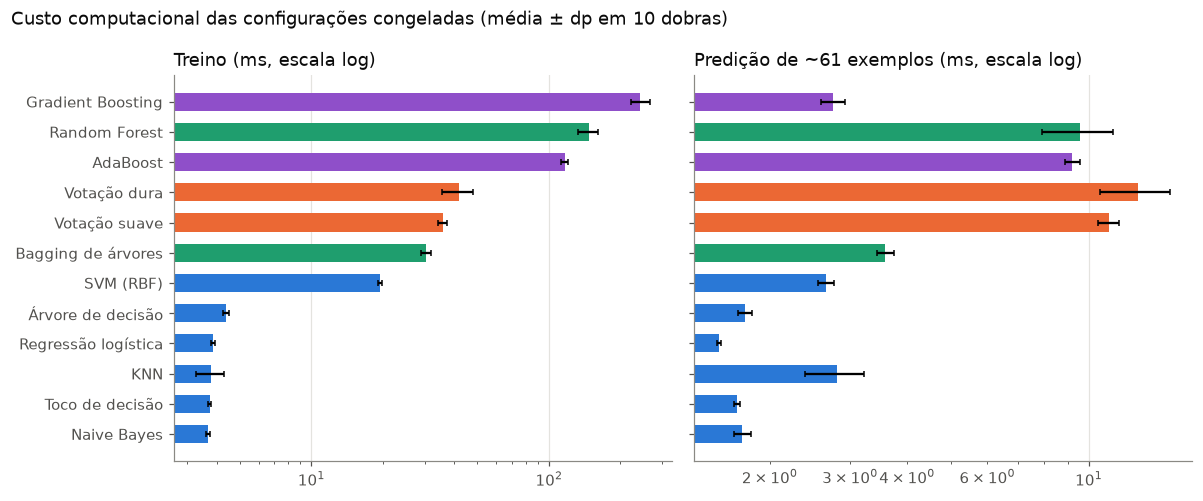

In [25]:
c = cost.drop(index=BASELINE).sort_values("treino_ms_media")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for ax, col, title in [(axes[0], "treino_ms", "Treino (ms, escala log)"), (axes[1], "predicao_ms", "Predição de ~61 exemplos (ms, escala log)")]:
    ax.barh(c.index, c[f"{col}_media"], xerr=c[f"{col}_dp"], color=[FAMILY_COLORS[f] for f in c["família"]], height=0.6, capsize=2)
    ax.set_xscale("log")
    ax.grid(axis="y", visible=False)
    ax.set_title(title, loc="left", color="#0b0b0b")
fig.suptitle("Custo computacional das configurações congeladas (média ± dp em 10 dobras)", x=0.01, ha="left", color="#0b0b0b")
fig.tight_layout()
fig.savefig(C.FIGURES_DIR / "02_custo.png")
plt.show()

## 13. Avaliação final no conjunto de teste (uso único)

Configurações congeladas na seção 11, ajustadas no treino inteiro (612) e avaliadas **uma única vez** nos 306 exemplos de teste. Dispersão: desvio-padrão por bootstrap (1000 reamostragens do teste, semente 42).

In [26]:
from tde2.data import load_test

X_test, y_test = load_test()

test_rows, test_pred = {}, {}
for n in [BASELINE] + ALTS:
    model = frozen[n].fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1] if E.has_proba(model) else None
    test_pred[n] = pred
    boot = E.bootstrap(y_test, pred)
    test_rows[n] = {
        "família": FAMILY[n],
        **E.scores(y_test, pred, proba),
        "balanced_accuracy_dp_bootstrap": boot.std(ddof=1),
        "balanced_accuracy_cv": results[n].folds[C.PRIMARY_METRIC].mean(),
    }
test_table = pd.DataFrame.from_dict(test_rows, orient="index").rename_axis("modelo")
test_table.to_csv(TABLES_DIR / "02_resultados_teste.csv")
test_table

/var/folders/gs/mt5h7_8n3914qmrf_hq5wjgr0000gn/T/ipykernel_65963/2811701229.py:3: UserWarning: Carregando o conjunto de TESTE. Ele deve ser usado uma única vez, ao final, depois que todas as configurações estiverem escolhidas.
  X_test, y_test = load_test()


,família,balanced_accuracy,f1_macro,recall_doenca,roc_auc,balanced_accuracy_dp_bootstrap,balanced_accuracy_cv
modelo,,,,,,,
Linha de base (classe majoritária),linha de base,0.500,0.356,1.000,0.500,0.000,0.500
Regressão logística,membro,0.873,0.874,0.899,0.934,0.019,0.851
KNN,membro,0.890,0.891,0.911,0.946,0.018,0.853
SVM (RBF),membro,0.876,0.877,0.905,0.934,0.019,0.841
Árvore de decisão,membro,0.838,0.838,0.852,0.883,0.021,0.821
Naive Bayes,membro,0.853,0.854,0.882,0.904,0.020,0.842
Toco de decisão,membro,0.808,0.808,0.828,0.808,0.022,0.811
Votação suave,heterogêneo,0.880,0.881,0.899,0.932,0.019,0.848
Votação dura,heterogêneo,0.881,0.881,0.893,NaN,0.018,0.849


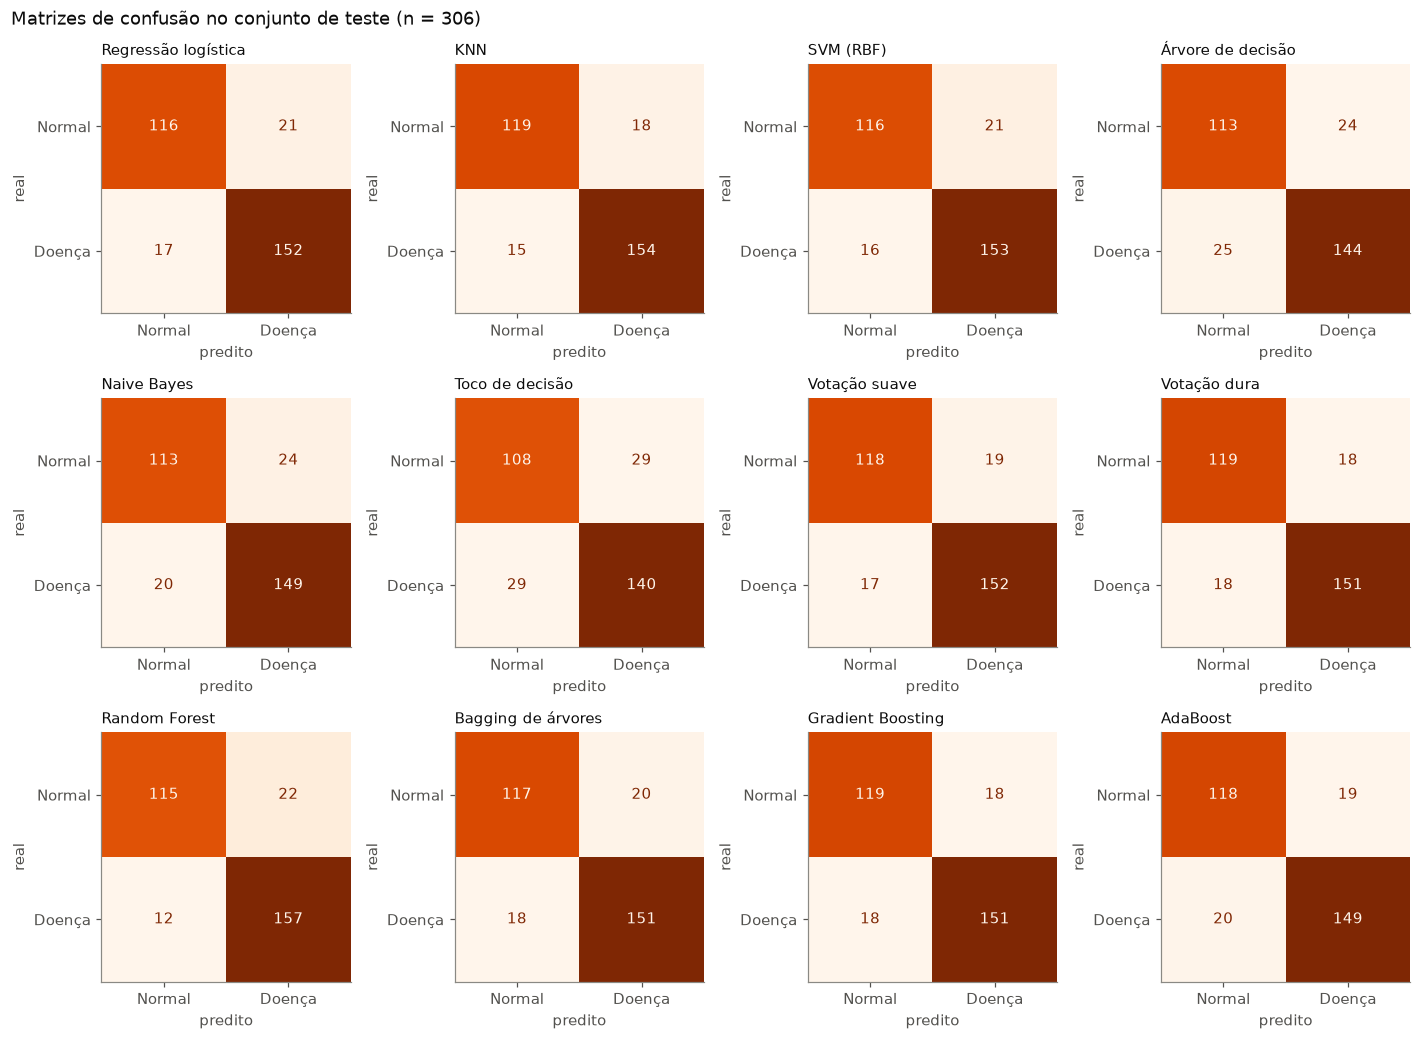

In [27]:
fig, axes = plt.subplots(3, 4, figsize=(13, 9.6))
for ax, n in zip(axes.flat, ALTS):
    ConfusionMatrixDisplay.from_predictions(
        y_test, test_pred[n], display_labels=labels, cmap="Oranges", colorbar=False, ax=ax
    )
    ax.set_title(n, loc="left", color="#0b0b0b", fontsize=10)
    ax.grid(False)
    ax.set_xlabel("predito")
    ax.set_ylabel("real")
fig.suptitle("Matrizes de confusão no conjunto de teste (n = 306)", x=0.01, ha="left", color="#0b0b0b")
fig.tight_layout()
fig.savefig(C.FIGURES_DIR / "02_matrizes_confusao_teste.png")
plt.show()

In [28]:
test_per_class = pd.DataFrame({
    n: E.per_class(E.Result(n, None, test_pred[n], None, [], [], None), y_test) for n in [BASELINE] + ALTS
}).T
test_per_class.to_csv(TABLES_DIR / "02_erros_por_classe_teste.csv")
test_per_class

,VN,FP,FN,VP,recall_Normal,recall_Doença cardíaca,precisão_doença
Linha de base (classe majoritária),0.0,137.0,0.0,169.0,0.000,1.000,0.552
Regressão logística,116.0,21.0,17.0,152.0,0.847,0.899,0.879
KNN,119.0,18.0,15.0,154.0,0.869,0.911,0.895
SVM (RBF),116.0,21.0,16.0,153.0,0.847,0.905,0.879
Árvore de decisão,113.0,24.0,25.0,144.0,0.825,0.852,0.857
Naive Bayes,113.0,24.0,20.0,149.0,0.825,0.882,0.861
Toco de decisão,108.0,29.0,29.0,140.0,0.788,0.828,0.828
Votação suave,118.0,19.0,17.0,152.0,0.861,0.899,0.889
Votação dura,119.0,18.0,18.0,151.0,0.869,0.893,0.893
Random Forest,115.0,22.0,12.0,157.0,0.839,0.929,0.877


## 14. Reprodutibilidade

In [29]:
pd.Series({
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "scipy": scipy.__version__,
    "semente": C.SEED,
    "dobras externas": C.N_SPLITS,
    "dobras internas": C.INNER_SPLITS,
    "n_iter por busca": C.N_ITER,
    "reamostragens bootstrap": C.N_BOOTSTRAP,
}, name="valor").to_frame()

,valor
python,3.12.15
numpy,2.5.5
pandas,3.1.1
scikit-learn,1.9.1
scipy,1.18.1
semente,42
dobras externas,10
dobras internas,5
n_iter por busca,20
reamostragens bootstrap,1000
